# Exploring the target (WorldCover) in GEE

## Introduction 

This notebook is designed to explore the training labels for my project and how to process the target, export and create sample points accurately.

In [2]:
import ee
import geemap
import matplotlib.pyplot as plt 

ee.Authenticate()
ee.Initialize(project='irp-zu')

### Displaying WorldCover

In [8]:
coastline_coords = [[-59.755689785228235, 8.126814578766439],
          [-57.833082363353235, 5.607387745118143],
          [-57.146881951761834, 5.898364580242008],
          [-57.009580630573, 6.02949062794878],
          [-56.888703240824334, 6.15511611857417],
          [-56.493195428324334, 6.624592088692309],
          [-56.416291131449334, 7.785376639618971],
          [-58.45482139063248, 9.543371065466095],
          [-59.98741416406998, 8.545208575574712]]

aoi_polygon = ee.Geometry.Polygon([coastline_coords])

start_date = "2020-01-01"
end_date = "2021-01-01"

dataset = ee.ImageCollection('ESA/WorldCover/v100').first().clip(aoi_polygon)
info = dataset.getInfo()
band = info['properties']  # the 'Map' band
print(list(zip(band['Map_class_values'], band['Map_class_names'])))
target = dataset.eq(95).selfMask()

visualization = {
    'bands': ['Map'],
}

m = geemap.Map()
m.center_object(aoi_polygon, 7)
m.add_layer(dataset, visualization, 'Landcover')
m.add_layer(target, {'palette': ['green']}, 'Mangroves')
m

dataset.projection().crs()
print("world_cover", dataset.projection().nominalScale().getInfo())

[(10, 'Tree cover'), (20, 'Shrubland'), (30, 'Grassland'), (40, 'Cropland'), (50, 'Built-up'), (60, 'Bare / sparse vegetation'), (70, 'Snow and ice'), (80, 'Permanent water bodies'), (90, 'Herbaceous wetland'), (95, 'Mangroves'), (100, 'Moss and lichen')]
world_cover 9.276624232772797


### Masking out water and creating a binary classification (Mangrove Non-mangrove)

Prototyping a Sentinel-2 input and WorldCover target label for 2020 for the guyana coastline

In [5]:
import pandas as pd

s2_bands = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']

# Cast S2 to float here so the label can stay integer (required by stratifiedSample)
s2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED") \
    .filterBounds(aoi_polygon) \
    .filterDate(start_date, end_date) \
    .select(s2_bands) \
    .median() \
    .toFloat()

# Binary label: 1=mangrove, 0=non-mangrove, water (class 80) masked out
water_mask = dataset.neq(80)
label = dataset.eq(95).rename('label').updateMask(water_mask)

stacked_image = s2.addBands(label)
stacked_image

### Trying exporting options - storing the combined dataset locally, on the google drive. 

- Stratified sampling - using 5000 points picked randomly from the guyana coastline and exporting the result with lat/lon coordinates associated. 
- Using batching to save to drive asynchronously to avoid memory limits

In [79]:
# Stratified sample: 2000 pixels per class (mangrove=1, non-mangrove=0, water masked)
# geemap.ee_to_df() times out on heavy computations — use batch export instead.

# https://developers.google.com/earth-engine/apidocs/ee-image-stratifiedsample
training_samples = stacked_image.stratifiedSample(
    numPoints=5000,
    classBand='label',
    region=aoi_polygon,
    scale=10,
    seed=42,
    tileScale=4,
    geometries=True
)

task = ee.batch.Export.table.toDrive(
    collection=training_samples,
    description='S2_WorldCover_Stratified_2000perClass',
    folder='EarthEngine_ML_Exports',
    fileFormat='CSV'
)
task.start()
print("Stratified sample export started!")
print(f"Task ID: {task.id}")

Stratified sample export started!
Task ID: 7O25OYTTFIZXWLBUF6ZXIV3K


### Script to download from the google drive to local machine for native analysis

In [80]:
# Download the exported CSV from Google Drive directly to local disk.
# Reference: https://deepnote.com/guides/google-cloud/how-to-download-files-from-google-drive-in-python

import time
import io
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload

output_path = 'data/local_training_data.csv'

# Poll until the batch task finishes
print("Waiting for export to complete...")
while task.status()['state'] in ['READY', 'RUNNING']:
    print(f"  {task.status()['state']}...")
    time.sleep(30)

if task.status()['state'] != 'COMPLETED':
    raise RuntimeError(f"Export failed: {task.status().get('error_message')}")

print("Export complete — downloading from Drive...")

# Reuse the credentials already established by ee.Authenticate()
creds = ee.data.get_persistent_credentials()
drive_service = build('drive', 'v3', credentials=creds)

# Find the exported file by name
results = drive_service.files().list(
    q="name='S2_WorldCover_Stratified_2000perClass.csv' and trashed=false",
    fields="files(id, name)"
).execute()

files = results.get('files', [])
if not files:
    raise FileNotFoundError("CSV not found in Drive — has the export task completed?")

file_id = files[0]['id']
request = drive_service.files().get_media(fileId=file_id)
with io.FileIO(output_path, 'wb') as fh:
    downloader = MediaIoBaseDownload(fh, request)
    done = False
    while not done:
        dl_status, done = downloader.next_chunk()
        print(f"  {int(dl_status.progress() * 100)}%")

print(f"Saved to {output_path}")

Waiting for export to complete...
  READY...
  RUNNING...
  RUNNING...
  RUNNING...
  RUNNING...
  RUNNING...
  RUNNING...
  RUNNING...
  RUNNING...
  RUNNING...
Export complete — downloading from Drive...
  100%
Saved to data/local_training_data.csv


### Examining the outputted CSV in a dataframe

In [6]:
# After the task completes, download the CSV from Drive and update this path
df = pd.read_csv('data/local_training_data.csv')
df

,system:index,B11,B12,B2,B3,B4,B8,label,.geo
0,0,2588.0000,2222.0000,4252.0000,4008.0000,3774.00000,4624.0000,0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
1,1,1902.0000,1466.0000,1891.0000,1694.0000,1537.50000,3460.1428,0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
2,2,2017.0000,1745.0000,2016.0000,2134.0000,1931.00000,3932.0000,0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
3,3,2683.0000,1834.0000,2532.0000,2729.0000,2456.00000,4212.0000,0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
4,4,1810.0000,1066.3334,1746.0000,1974.0000,1652.00000,3415.0000,0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
...,...,...,...,...,...,...,...,...,...
9995,9995,1790.5000,1366.7500,1903.0000,1912.0000,1693.00000,3755.0000,1,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
9996,9996,1429.5000,661.5000,544.2500,782.7500,536.20000,3222.6667,1,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
9997,9997,1779.2500,1229.0000,1173.6000,1368.6666,1183.50000,3587.0000,1,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
9998,9998,1725.9166,942.0000,603.1667,797.5714,703.23334,2772.6667,1,"{""geodesic"":false,""type"":""Point"",""coordinates""..."


### Prototype Random Forest Model to estimate the best number of samples to use in the model

I think 2000 samples is fairly adequate and prevent severe wait times using the learning curve

n=  100 per class | F1: 0.874 ± 0.041
n=  250 per class | F1: 0.888 ± 0.024
n=  500 per class | F1: 0.908 ± 0.034
n= 1000 per class | F1: 0.921 ± 0.011
n= 2000 per class | F1: 0.920 ± 0.007
n= 3000 per class | F1: 0.923 ± 0.013
n= 4000 per class | F1: 0.923 ± 0.005
n= 5000 per class | F1: 0.921 ± 0.007


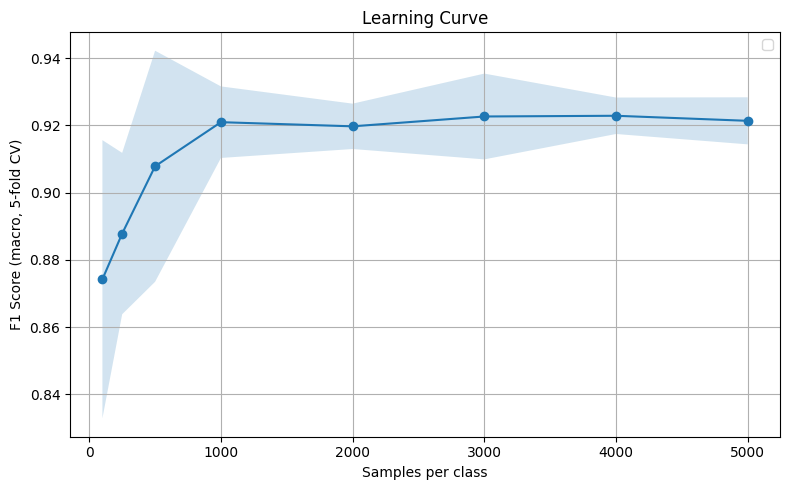

Train size: 8000 | Test size (held out): 2000


In [8]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split

feature_cols = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']
X = df[feature_cols].values
y = df['label'].values

# Hold out 20% as a test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

sample_sizes = [100, 250, 500, 1000, 2000, 3000, 4000, 5000]
mean_scores, std_scores = [], []

for n in sample_sizes:
    idx = []
    for cls in np.unique(y_train):
        cls_idx = np.where(y_train == cls)[0]
        idx.extend(np.random.choice(cls_idx, min(n, len(cls_idx)), replace=False))

    X_sub, y_sub = X_train[idx], y_train[idx]
    clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    scores = cross_val_score(clf, X_sub, y_sub,
                             cv=StratifiedKFold(6, shuffle=True, random_state=42),
                             scoring='f1_macro')
    mean_scores.append(scores.mean())
    std_scores.append(scores.std())
    print(f"n={n:>5} per class | F1: {scores.mean():.3f} ± {scores.std():.3f}")

mean_scores, std_scores = np.array(mean_scores), np.array(std_scores)

plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, mean_scores, 'o-')
plt.fill_between(sample_sizes, mean_scores - std_scores, mean_scores + std_scores, alpha=0.2)
plt.xlabel('Samples per class')
plt.ylabel('F1 Score (macro, 5-fold CV)')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Train size: {len(X_train)} | Test size (held out): {len(X_test)}")

### Confusion Matrix on the Test Test 
- split is on randomly chosen pixels, class distributions are respected

              precision    recall  f1-score   support

Non-mangrove       0.91      0.92      0.92      1000
    Mangrove       0.92      0.91      0.92      1000

    accuracy                           0.92      2000
   macro avg       0.92      0.92      0.92      2000
weighted avg       0.92      0.92      0.92      2000



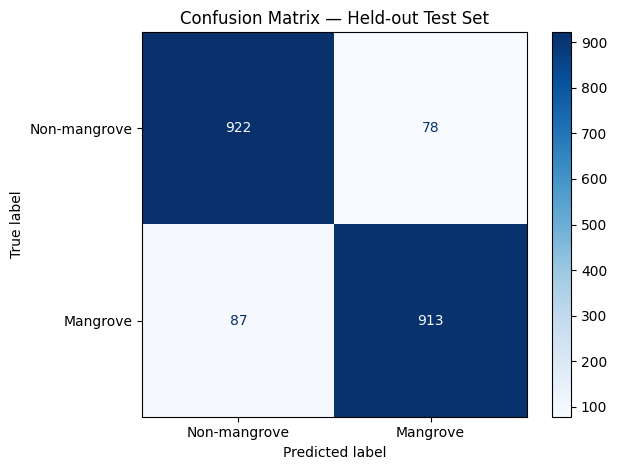

In [10]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Train final model on best_n samples per class from the full training set
idx = []
for cls in np.unique(y_train):
    cls_idx = np.where(y_train == cls)[0]
    idx.extend(np.random.choice(cls_idx, min(2000, len(cls_idx)), replace=False))

clf_final = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf_final.fit(X_train[idx], y_train[idx])

# Evaluate on the held-out test set
y_pred = clf_final.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Non-mangrove', 'Mangrove']))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-mangrove', 'Mangrove'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix — Held-out Test Set')
plt.tight_layout()
plt.show()

### Spatial spliting, holding out a region in each cross-validation fold

- Comparing F1 scores between random splitting vs. spatial splitting

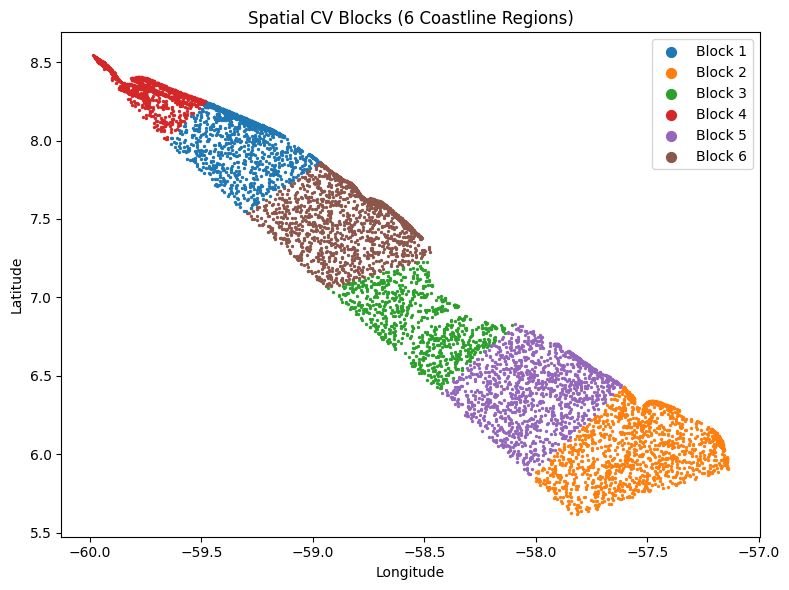

      n_dropped     f1  precision_nonmang  recall_nonmang  precision_mang  recall_mang
fold                                                                                  
1            31  0.904              0.952           0.813           0.892        0.974
2             1  0.944              0.944           0.974           0.954        0.906
3             3  0.733              0.987           0.861           0.395        0.886
4            20  0.573              0.224           0.936           0.989        0.648
5             2  0.957              0.996           0.972           0.885        0.981
6             5  0.914              0.951           0.874           0.882        0.954

Mean across folds:
n_dropped            10.333
f1                    0.837
precision_nonmang     0.842
recall_nonmang        0.905
precision_mang        0.833
recall_mang           0.892

Random CV F1: 0.92 — Gap: 0.083


In [11]:
import json
from sklearn.cluster import KMeans
from sklearn.metrics import f1_score, precision_score, recall_score
from scipy.spatial import cKDTree

# Parse lon/lat from the .geo column
coords = df['.geo'].apply(lambda x: json.loads(x)['coordinates'])
lon = coords.apply(lambda x: x[0]).values
lat = coords.apply(lambda x: x[1]).values

# 6 spatial blocks to match the 6 coastline regions
# https://www.youtube.com/watch?v=4b5d3muPQmA
k = 6
spatial_folds = KMeans(n_clusters=k, random_state=42, n_init=10) \
    .fit_predict(np.column_stack([lon, lat]))

# Visualise the spatial blocks so you can see they're geographically separated
plt.figure(figsize=(8, 6))
for fold in range(k):
    mask = spatial_folds == fold
    plt.scatter(lon[mask], lat[mask], s=2, label=f'Block {fold + 1}')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Spatial CV Blocks (6 Coastline Regions)')
plt.legend(markerscale=5)
plt.tight_layout()
plt.show()

feature_cols = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']
X = df[feature_cols].values
y = df['label'].values

# 1km buffer — drop training points within this distance of the test region border
# to avoid spatial leakage at block boundaries

# circumference of the Earth divided by 360 degrees:
# 40,075 km ÷ 360° ≈ 111.3 km per degree
buffer_deg = 1.0 / 111.0
all_coords = np.column_stack([lon, lat])

results = []
for fold in range(k):
    test_mask  = spatial_folds == fold
    train_mask = spatial_folds != fold

    # Build tree from test points, find training points within buffer distance
    tree = cKDTree(all_coords[test_mask])
    too_close = np.array([
        len(tree.query_ball_point(pt, r=buffer_deg)) > 0
        for pt in all_coords[train_mask]
    ])

    # Remove border training points before fitting
    valid_train_idx = np.where(train_mask)[0][~too_close]
    n_dropped = too_close.sum()

    clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    clf.fit(X[valid_train_idx], y[valid_train_idx])
    y_pred = clf.predict(X[test_mask])

    results.append({
        'fold':              fold + 1,
        'n_dropped':         n_dropped,
        'f1':                f1_score(y[test_mask], y_pred, average='macro'),
        'precision_nonmang': precision_score(y[test_mask], y_pred, pos_label=0),
        'recall_nonmang':    recall_score(y[test_mask], y_pred, pos_label=0),
        'precision_mang':    precision_score(y[test_mask], y_pred, pos_label=1),
        'recall_mang':       recall_score(y[test_mask], y_pred, pos_label=1),
    })

results_df = pd.DataFrame(results).set_index('fold')
print(results_df.round(3).to_string())
print(f"\nMean across folds:")
print(results_df.mean().round(3).to_string())
print(f"\nRandom CV F1: 0.92 — Gap: {0.92 - results_df['f1'].mean():.3f}")

### Overlaying the coastal regions of Guyana onto the spatial splitting plot

In [12]:
# https://developers.google.com/earth-engine/datasets/catalog/WM_geoLab_geoBoundaries_600_ADM1#table-schema

geo_map = geemap.Map(basemap='ROADMAP')

geo_boundaries = ee.FeatureCollection('WM/geoLab/geoBoundaries/600/ADM1').filter(ee.Filter.eq('shapeGroup', 'GUY'))
styled_boundaries = geo_boundaries.style(
    color='00909F', width=1.0, fillColor='white'
);

geo_map.center_object(aoi_polygon, 6);
geo_map.addLayer(styled_boundaries, {}, 'ADM2 Boundaries');

region_names = geo_boundaries.aggregate_array('shapeName').getInfo()
region_names

['Barina-Waini',
 'Pomeroon-Supenaam',
 'Essequibo Islands-West Demerara',
 'Demerara-Mahaica',
 'Cuyuni-Mazaruni',
 'Potaro-Siparuni',
 'Upper Takutu-Upper Essequibo',
 'Mahaica-Berbice',
 'East Berbice-Corentyne',
 'Upper Demerara-Berbice']

In [13]:
coastal_regions = ['Barina-Waini', 
                   'Pomeroon-Supenaam', 
                   'Essequibo Islands-West Demerara', 
                   'Demerara-Mahaica', 
                   'Mahaica-Berbice', 
                   'East Berbice-Corentyne']

highlight_style = {
    'color': 'ff0000', 
    'width': 1.5,
    'fillColor': '00000000'
}

for idx, region in enumerate(coastal_regions):
    highlighted_region = geo_boundaries.filter(ee.Filter.eq('shapeName', region))
    geo_map.addLayer(highlighted_region.style(**highlight_style), {}, f'Region {idx + 1} - {region}')

geo_map

Map(center=[7.625000281267503, -58.02523831094688], controls=(WidgetControl(options=['position', 'transparent_…

In [14]:
from ipyleaflet import CircleMarker, LayerGroup

colors = ['red', 'blue', 'green', 'purple', 'orange', 'darkred']

for fold in range(k):
    mask = spatial_folds == fold
    fold_lon = lon[mask]
    fold_lat = lat[mask]

    # Subsample to ~300 points per block 
    step = max(1, len(fold_lon) // 300)

    markers = [
        CircleMarker(
            location=[la, lo],
            radius=4,
            color=colors[fold],
            fill_color=colors[fold],
            fill_opacity=0.8,
            weight=1
        )
        for lo, la in zip(fold_lon[::step], fold_lat[::step])
    ]

    geo_map.add(LayerGroup(layers=markers, name=f'CV Block {fold + 1}'))

geo_map

Map(bottom=4111.0, center=[12.424380926602517, -52.690671780878496], controls=(WidgetControl(options=['positio…

### Visualization showing how KDTree is able to drop bordering pixels from the training set 

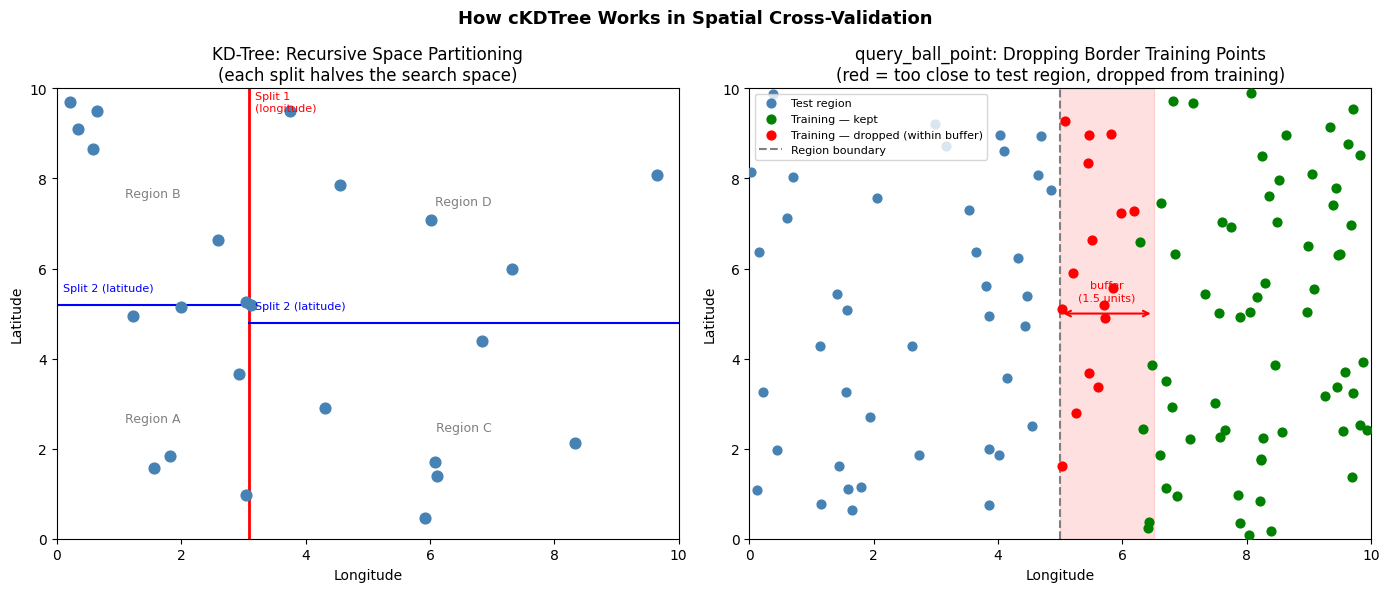

In [15]:
import matplotlib.patches as patches
from scipy.spatial import cKDTree

np.random.seed(42)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Panel 1: KD-Tree recursive space partitioning ---
ax1 = axes[0]
pts = np.random.uniform(0, 10, (24, 2))
ax1.scatter(pts[:, 0], pts[:, 1], s=60, color='steelblue', zorder=3)

# Level 1 split — along longitude (x) median
x_mid = np.median(pts[:, 0])
ax1.axvline(x_mid, color='red', linewidth=2)
ax1.text(x_mid + 0.1, 9.5, 'Split 1\n(longitude)', color='red', fontsize=8)

# Level 2 splits — along latitude (y) median within each half
left  = pts[pts[:, 0] <= x_mid]
right = pts[pts[:, 0] >  x_mid]
y_mid_left  = np.median(left[:, 1])
y_mid_right = np.median(right[:, 1])
ax1.plot([0, x_mid],  [y_mid_left,  y_mid_left],  color='blue', linewidth=1.5)
ax1.plot([x_mid, 10], [y_mid_right, y_mid_right], color='blue', linewidth=1.5)
ax1.text(0.1, y_mid_left  + 0.3, 'Split 2 (latitude)', color='blue', fontsize=8)
ax1.text(x_mid + 0.1, y_mid_right + 0.3, 'Split 2 (latitude)', color='blue', fontsize=8)

# Label the 4 resulting regions
ax1.text(x_mid / 2,        y_mid_left / 2,          'Region A', ha='center', fontsize=9, color='gray')
ax1.text(x_mid / 2,        (y_mid_left + 10) / 2,   'Region B', ha='center', fontsize=9, color='gray')
ax1.text((x_mid + 10) / 2, y_mid_right / 2,          'Region C', ha='center', fontsize=9, color='gray')
ax1.text((x_mid + 10) / 2, (y_mid_right + 10) / 2,  'Region D', ha='center', fontsize=9, color='gray')

ax1.set_xlim(0, 10)
ax1.set_ylim(0, 10)
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
ax1.set_title('KD-Tree: Recursive Space Partitioning\n(each split halves the search space)')

# --- Panel 2: query_ball_point — buffer zone in spatial CV ---
ax2 = axes[1]
boundary_x = 5.0
buffer = 1.5

test_pts  = np.random.uniform([0, 0], [boundary_x, 10], (40, 2))
train_pts = np.random.uniform([boundary_x, 0], [10, 10], (80, 2))

tree = cKDTree(test_pts)
too_close = np.array([len(tree.query_ball_point(pt, r=buffer)) > 0 for pt in train_pts])

ax2.scatter(test_pts[:, 0], test_pts[:, 1],
            s=40, color='steelblue', label='Test region', zorder=3)
ax2.scatter(train_pts[~too_close, 0], train_pts[~too_close, 1],
            s=40, color='green', label='Training — kept', zorder=3)
ax2.scatter(train_pts[too_close, 0], train_pts[too_close, 1],
            s=40, color='red', label='Training — dropped (within buffer)', zorder=3)

ax2.axvline(boundary_x, color='gray', linestyle='--', linewidth=1.5, label='Region boundary')
ax2.add_patch(patches.Rectangle(
    (boundary_x, 0), buffer, 10, alpha=0.12, color='red'
))
ax2.annotate('', xy=(boundary_x + buffer, 5), xytext=(boundary_x, 5),
             arrowprops=dict(arrowstyle='<->', color='red', lw=1.5))
ax2.text(boundary_x + buffer / 2, 5.3, f'buffer\n({buffer} units)',
         color='red', ha='center', fontsize=8)

ax2.set_xlim(0, 10)
ax2.set_ylim(0, 10)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')
ax2.set_title('query_ball_point: Dropping Border Training Points\n(red = too close to test region, dropped from training)')
ax2.legend(fontsize=8, loc='upper left')

plt.suptitle('How cKDTree Works in Spatial Cross-Validation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()